# 04 · Preprocesamiento, ingeniería y selección de variables (T17 · T18)

Este notebook implementa y evalúa las estrategias de preprocesamiento **P1, P2 y P3** (T17) y el análisis de **ingeniería de variables, comparación de selectores en CV y ablación de `furnishingstatus`** (T18), trabajando exclusivamente sobre las **436 filas de entrenamiento** (sin tocar el 20 % sellado de prueba).

## 1. Preparación del entorno

La siguiente celda funciona igual en **Google Colab** y en **local**: en Colab clona el repositorio e instala las dependencias; en local ubica la raíz del repositorio para poder importar `src/`.

In [1]:
# --- Preparación del entorno (Colab o local) ---
import os
import subprocess
import sys
from pathlib import Path

EN_COLAB = "google.colab" in sys.modules  # True si el notebook corre en Google Colab

if EN_COLAB:
    from google.colab import userdata

    repo = "github.com/Juanm0331123/ml-precio-vivienda.git"
    try:
        url = f"https://{userdata.get('GITHUB_TOKEN')}@{repo}"
    except Exception:
        url = f"https://{repo}"
    if not Path("ml-precio-vivienda").exists():
        subprocess.run(["git", "clone", "-q", url], check=True)
    os.chdir("ml-precio-vivienda")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))
print("Raíz del proyecto:", RAIZ)

Raíz del proyecto: C:\Users\Windows 11\Desktop\ml-precio-vivienda


In [2]:
# --- Librerías y configuración compartida ---
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline

from src.config import DIR_FIGURAS, DIR_TABLAS, SEMILLA
from src.evaluacion import cargar_entrenamiento, crear_pliegues
from src.preprocesamiento import (
    COLUMNAS_BINARIAS,
    COLUMNAS_CONTEOS,
    COLUMNAS_DERIVADAS,
    COLUMNAS_NUMERICAS,
    COLUMNAS_PREDICTORAS,
    CodificadorBase,
    DerivadorVariables,
    Winsorizador,
    construir_preprocesamiento,
    envolver_objetivo,
    nombres_seleccionados,
)

np.random.seed(SEMILLA)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_theme(style="whitegrid", context="notebook")
DIR_FIGURAS.mkdir(parents=True, exist_ok=True)
DIR_TABLAS.mkdir(parents=True, exist_ok=True)

## 2. Carga aislada del entrenamiento y partición dentro del fold

Por regla crítica del proyecto (`T06`), el 20 % sellado (`prueba`, 109 filas) **no se carga en memoria** hasta la evaluación final (`T25`).  
Usamos `cargar_entrenamiento()` para cargar exclusivamente las 436 filas de `entrenamiento` y tomamos el primer pliegue estratificado (`crear_pliegues(y)[0]`) como separación `train_fold` (ajuste) vs `val_fold` (validación) para demostrar que todo `fit` ocurre únicamente sobre entrenamiento sin fuga de información.

In [3]:
X, y, evidencia = cargar_entrenamiento()
pliegues = crear_pliegues(y)
idx_train, idx_val = pliegues[0]

X_train, y_train = X.iloc[idx_train].copy(), y.iloc[idx_train].copy()
X_val, y_val = X.iloc[idx_val].copy(), y.iloc[idx_val].copy()

print("Evidencia de aislamiento del test sellado:")
for k, v in evidencia.items():
    print(f"  - {k}: {v}")
print(f"\nPliegue 0 -> train_fold: {X_train.shape}, val_fold: {X_val.shape}")

Evidencia de aislamiento del test sellado:
  - n_entrenamiento_cargado: 436
  - n_prueba_en_particion: 109
  - n_prueba_cargado: 0
  - interseccion_ids_entrenamiento_prueba: 0
  - sha256_particion: 7c34c251279e7f15b21853d58b37f953f37d56f7aead93a3ef99c50d24013f1f
  - sha256_housing_limpio: e69841956c4328574faa12d5888d056a48ebd55bb5ff0ece69c9c6ba60bb53d5
  - semilla: 5007

Pliegue 0 -> train_fold: (348, 12), val_fold: (88, 12)


## 3. Verificación de codificación base (`yes/no → 0/1`)

El módulo `src/preprocesamiento.py` incorpora `CodificadorBase` como primer paso de los tres pipelines (`P1`, `P2`, `P3`). Este transformador es **idempotente**:
- Si recibe los datos limpios de `T06` (`housing_limpio.csv`, donde las binarias ya son `0/1` y `furnishingstatus` es `0/1/2`), los conserva sin cambios.
- Si recibe datos crudos con cadenas (`yes`/`no` y `unfurnished`/`semi-furnished`/`furnished`), aplica los mapeos deterministas `MAPA_BINARIO` y `MAPA_AMOBLADO`.

Como son reglas fijas por fila, no aprenden estadísticos de la muestra ni pueden filtrar información entre pliegues.

In [4]:
def resumen_distribucion(df: pd.DataFrame, columnas=None) -> pd.DataFrame:
    """Calcula media, desviación estándar, mediana, IQR, mínimo, máximo y asimetría."""
    cols = columnas if columnas is not None else df.columns
    filas = []
    for c in cols:
        s = pd.Series(df[c], dtype=float)
        q25, q75 = s.quantile(0.25), s.quantile(0.75)
        filas.append({
            "variable": c,
            "media": s.mean(),
            "desv": s.std(ddof=1),
            "mediana": s.median(),
            "iqr": q75 - q25,
            "min": s.min(),
            "max": s.max(),
            "asimetria": stats.skew(s, bias=False),
        })
    return pd.DataFrame(filas)

resumen_antes = resumen_distribucion(X_train, COLUMNAS_NUMERICAS)
print("Estadísticos originales de las variables numéricas (train_fold):")
display(resumen_antes)

Estadísticos originales de las variables numéricas (train_fold):


,variable,media,desv,mediana,iqr,min,max,asimetria
0,area,"5,126.0287","2,100.5384","4,530.0000","2,732.5000","1,650.0000","15,600.0000",1.2052
1,bedrooms,2.9253,0.7163,3.0000,1.0000,1.0000,6.0000,0.5366
2,bathrooms,1.2759,0.4906,1.0000,1.0000,1.0000,3.0000,1.5115
3,stories,1.7931,0.8507,2.0000,1.0000,1.0000,4.0000,1.0309
4,parking,0.6379,0.8494,0.0000,1.0000,0.0000,3.0000,0.9670


## 4. Estrategia P1 · Base (`OneHotEncoder` + `StandardScaler`)

La estrategia **P1** sirve como línea base comparable:
1. **Binarias (`6`):** `yes/no → 0/1` (vía `CodificadorBase`, sin escalar).
2. **`furnishingstatus`:** `OneHotEncoder(drop="first")` sobre `{0, 1, 2}` (evita colinealidad perfecta en OLS y Ridge; genera 2 columnas binarias).
3. **Numéricas (`5`):** `StandardScaler` (`(x - μ) / σ`) ajustado exclusivamente en `train_fold`.
4. **Objetivo (`price`):** se mantiene en su escala original.

In [5]:
pre_p1 = construir_preprocesamiento("P1", escalar=True)
X_train_p1 = pre_p1.fit_transform(X_train, y_train)
X_val_p1 = pre_p1.transform(X_val)

print(f"P1 -> train: {X_train_p1.shape} | val: {X_val_p1.shape}")
print("Columnas P1:", list(X_train_p1.columns))
assert list(X_train_p1.columns) == list(X_val_p1.columns)
assert not X_train_p1.isna().any().any() and not X_val_p1.isna().any().any()

resumen_p1 = resumen_distribucion(X_train_p1, COLUMNAS_NUMERICAS)
display(resumen_p1)

P1 -> train: (348, 13) | val: (88, 13)
Columnas P1: ['area', 'bedrooms', 'bathrooms', 'stories', 'parking', 'furnishingstatus_1', 'furnishingstatus_2', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea']


,variable,media,desv,mediana,iqr,min,max,asimetria
0,area,-0.0000,1.0014,-0.2842,1.3027,-1.6572,4.9935,1.2052
1,bedrooms,-0.0000,1.0014,0.1044,1.3980,-2.6916,4.2985,0.5366
2,bathrooms,-0.0000,1.0014,-0.5631,2.0413,-0.5631,3.5194,1.5115
3,stories,-0.0000,1.0014,0.2436,1.1772,-0.9337,2.5980,1.0309
4,parking,-0.0000,1.0014,-0.7521,1.1789,-0.7521,2.7847,0.9670


**Comentario sobre P1:**  
Al comparar las tablas antes y después de `P1`, se observa que `StandardScaler` centra todas las numéricas en **media = 0** y **desviación estándar ≈ 1** (`1.0014` por `ddof=1`), pero **la asimetría no cambia en absoluto** (p. ej., `area` mantiene exactamente su asimetría original positiva > 1.2). Esto ocurre porque el escalado lineal es una transformación afín que preserva la forma de la distribución y la influencia de la cola derecha.

## 5. Estrategia P2 · Transformaciones (`log(price)`, `Yeo-Johnson` en `area`, `RobustScaler`)

La estrategia **P2** ataca las asimetrías y la sensibilidad a valores extremos detectadas en el EDA (`02_eda.ipynb`):
1. **Objetivo `price`:** transformación logarítmica `log(price)` mediante `TransformedTargetRegressor(func=np.log, inverse_func=np.exp)` (`envolver_objetivo`), de modo que el modelo aprende en escala logarítmica y predice de vuelta en la escala original.
2. **Tamaño del lote (`area`):** `PowerTransformer(method="yeo-johnson")` ajustado solo con `train_fold` (estima el exponente λ y estandariza).
3. **Conteos (`bedrooms`, `bathrooms`, `stories`, `parking`):** `RobustScaler` (centra en mediana y escala por IQR, robusto ante valores extremos).

In [6]:
pre_p2 = construir_preprocesamiento("P2", escalar=True)
X_train_p2 = pre_p2.fit_transform(X_train, y_train)
X_val_p2 = pre_p2.transform(X_val)

print(f"P2 -> train: {X_train_p2.shape} | val: {X_val_p2.shape}")
assert list(X_train_p2.columns) == list(X_val_p2.columns)
assert not X_train_p2.isna().any().any() and not X_val_p2.isna().any().any()

# Parámetro lambda aprendido por Yeo-Johnson en 'area'
lam_area = pre_p2.named_steps["columnas"].named_transformers_["area"].lambdas_[0]
print(f"Exponente lambda (Yeo-Johnson) aprendido en 'area' (solo train_fold): {lam_area:.4f}")

# Verificación de TransformedTargetRegressor en P2
modelo_p2 = envolver_objetivo(Pipeline([("prepro", construir_preprocesamiento("P2", True)), ("reg", Ridge())]), "P2")
modelo_p2.fit(X_train, y_train)
pred_p2 = modelo_p2.predict(X_val)
print(f"Predicciones P2 (escala original): media={pred_p2.mean():,.0f}, rango=[{pred_p2.min():,.0f}, {pred_p2.max():,.0f}]")

resumen_p2 = resumen_distribucion(X_train_p2, COLUMNAS_NUMERICAS)
display(resumen_p2)

P2 -> train: (348, 13) | val: (88, 13)
Exponente lambda (Yeo-Johnson) aprendido en 'area' (solo train_fold): -0.0314
Predicciones P2 (escala original): media=4,809,801, rango=[2,713,064, 8,673,524]


,variable,media,desv,mediana,iqr,min,max,asimetria
0,area,-0.0000,1.0014,-0.1103,1.4246,-2.7180,2.9730,0.0007
1,bedrooms,-0.0747,0.7163,0.0000,1.0000,-2.0000,3.0000,0.5366
2,bathrooms,0.2759,0.4906,0.0000,1.0000,0.0000,2.0000,1.5115
3,stories,-0.2069,0.8507,0.0000,1.0000,-1.0000,2.0000,1.0309
4,parking,0.6379,0.8494,0.0000,1.0000,0.0000,3.0000,0.9670


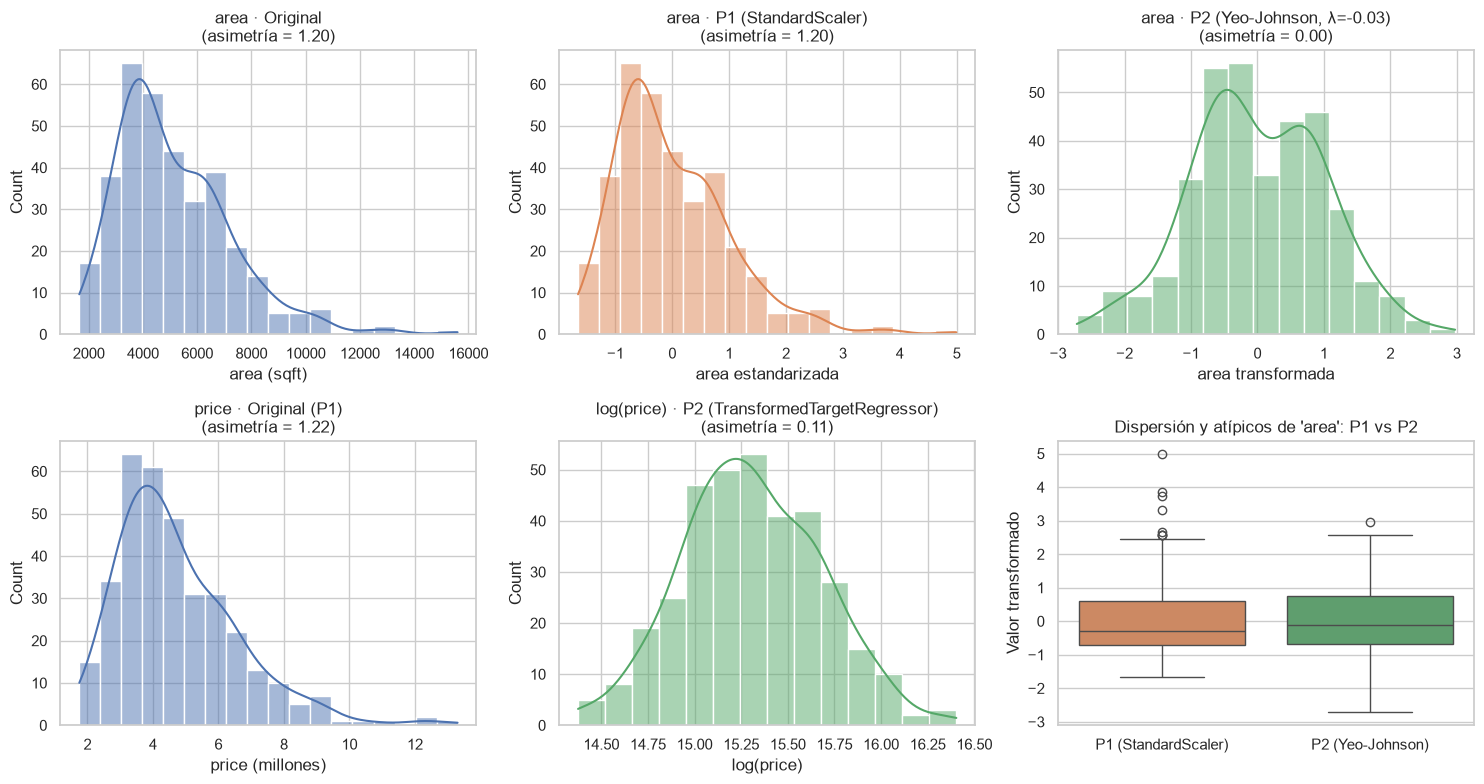

Figura guardada en: C:\Users\Windows 11\Desktop\ml-precio-vivienda\reports\figures\fig_prepro_p1_p2_area_precio.png


In [7]:
# --- Figura 1: Comparación antes vs P1 vs P2 en 'area' y 'price' ---
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

# Fila 1: Variable predictora 'area'
sns.histplot(X_train["area"], kde=True, ax=axes[0, 0], color="#4C72B0")
axes[0, 0].set_title(f"area · Original\n(asimetría = {stats.skew(X_train['area']):.2f})")
axes[0, 0].set_xlabel("area (sqft)")

sns.histplot(X_train_p1["area"], kde=True, ax=axes[0, 1], color="#DD8452")
axes[0, 1].set_title(f"area · P1 (StandardScaler)\n(asimetría = {stats.skew(X_train_p1['area']):.2f})")
axes[0, 1].set_xlabel("area estandarizada")

sns.histplot(X_train_p2["area"], kde=True, ax=axes[0, 2], color="#55A868")
axes[0, 2].set_title(f"area · P2 (Yeo-Johnson, λ={lam_area:.2f})\n(asimetría = {stats.skew(X_train_p2['area']):.2f})")
axes[0, 2].set_xlabel("area transformada")

# Fila 2: Variable objetivo 'price' y comparación de conteos (P1 vs P2)
sns.histplot(y_train / 1e6, kde=True, ax=axes[1, 0], color="#4C72B0")
axes[1, 0].set_title(f"price · Original (P1)\n(asimetría = {stats.skew(y_train):.2f})")
axes[1, 0].set_xlabel("price (millones)")

log_y = np.log(y_train)
sns.histplot(log_y, kde=True, ax=axes[1, 1], color="#55A868")
axes[1, 1].set_title(f"log(price) · P2 (TransformedTargetRegressor)\n(asimetría = {stats.skew(log_y):.2f})")
axes[1, 1].set_xlabel("log(price)")

# Boxplot comparativo de 'area' en P1 vs P2
df_box = pd.DataFrame({"P1 (StandardScaler)": X_train_p1["area"], "P2 (Yeo-Johnson)": X_train_p2["area"]})
sns.boxplot(data=df_box, ax=axes[1, 2], palette=["#DD8452", "#55A868"])
axes[1, 2].set_title("Dispersión y atípicos de 'area': P1 vs P2")
axes[1, 2].set_ylabel("Valor transformado")

plt.tight_layout()
ruta_fig1 = DIR_FIGURAS / "fig_prepro_p1_p2_area_precio.png"
fig.savefig(ruta_fig1, dpi=150, bbox_inches="tight")
plt.show()
print("Figura guardada en:", ruta_fig1)

**Comentario sobre P2:**  
1. En `area`, `PowerTransformer(method="yeo-johnson")` reduce drásticamente la asimetría hacia un valor cercano a cero (distribución prácticamente simétrica y acampanada) y elimina los atípicos extremos de la cola derecha visibles en el boxplot de P1.
2. En el objetivo `price`, el logaritmo (`log(price)`) pasa de una asimetría marcada (> 1.1) a una distribución casi simétrica, estabilizando la varianza de los residuos para modelos lineales y basados en distancia/kernel.
3. En los conteos (`bedrooms`, `bathrooms`, `stories`, `parking`), `RobustScaler` conserva la forma discreta centrada en la mediana (0) y escalada por el rango intercuartílico.

## 6. Estrategia P3 · Ingeniería y robustez (derivadas, winsorización en el fold y selección)

La estrategia **P3** añade sobre P2:
1. **Variables derivadas (`DerivadorVariables`):**
   - `area_por_dormitorio = area / bedrooms`
   - `n_comodidades = guestroom + basement + hotwaterheating + airconditioning`
   - `area_x_prefarea = area * prefarea`
   - `area_x_airconditioning = area * airconditioning`
2. **Winsorización (`Winsorizador(1, 99)`):** aprende los percentiles 1 % y 99 % **dentro del fold de entrenamiento** y recorta `area` (antes de Yeo-Johnson) y las 4 variables derivadas (antes de `StandardScaler`).
3. **Selección de variables (`SelectKBest`):** selecciona las `k = 10` mejores variables según `mutual_info_regression` (ajustada solo con `train_fold`).

In [8]:
pre_p3 = construir_preprocesamiento("P3", escalar=True)
X_train_p3 = pre_p3.fit_transform(X_train, y_train)
X_val_p3 = pre_p3.transform(X_val)

seleccionadas_p3 = nombres_seleccionados(pre_p3)
print(f"P3 -> train: {X_train_p3.shape} | val: {X_val_p3.shape}")
print(f"Variables seleccionadas (k={len(seleccionadas_p3)}): {seleccionadas_p3}")
assert X_train_p3.shape[1] == X_val_p3.shape[1] == 10
assert not np.isnan(np.asarray(X_train_p3, dtype=float)).any()
assert not np.isnan(np.asarray(X_val_p3, dtype=float)).any()

P3 -> train: (348, 10) | val: (88, 10)
Variables seleccionadas (k=10): ['area', 'bedrooms', 'bathrooms', 'stories', 'parking', 'area_por_dormitorio', 'n_comodidades', 'area_x_prefarea', 'area_x_airconditioning', 'airconditioning']


In [9]:
# --- Comparación del efecto de Winsorizador(1, 99) en 'area' y variables derivadas ---
X_deriv_raw = DerivadorVariables().fit_transform(CodificadorBase().fit_transform(X_train))
cols_winsor = ["area"] + COLUMNAS_DERIVADAS

win = Winsorizador(1, 99).fit(X_deriv_raw[cols_winsor])
X_deriv_win = pd.DataFrame(win.transform(X_deriv_raw[cols_winsor]), columns=cols_winsor, index=X_deriv_raw.index)

comp_win = pd.DataFrame({
    "variable": cols_winsor,
    "min_antes": [X_deriv_raw[c].min() for c in cols_winsor],
    "min_winsor": [X_deriv_win[c].min() for c in cols_winsor],
    "max_antes": [X_deriv_raw[c].max() for c in cols_winsor],
    "max_winsor": [X_deriv_win[c].max() for c in cols_winsor],
    "asim_antes": [stats.skew(X_deriv_raw[c]) for c in cols_winsor],
    "asim_winsor": [stats.skew(X_deriv_win[c]) for c in cols_winsor],
})
display(comp_win)

,variable,min_antes,min_winsor,max_antes,max_winsor,asim_antes,asim_winsor
0,area,"1,650.0000","1,926.1500","15,600.0000","11,436.7000",1.2000,0.8812
1,area_por_dormitorio,381.0000,557.8333,"6,600.0000","4,867.6100",1.5731,1.1963
2,n_comodidades,0.0000,0.0000,3.0000,3.0000,0.7039,0.7039
3,area_x_prefarea,0.0000,0.0000,"12,090.0000","10,108.4000",1.6726,1.6307
4,area_x_airconditioning,0.0000,0.0000,"15,600.0000","9,087.9800",1.2576,1.0825


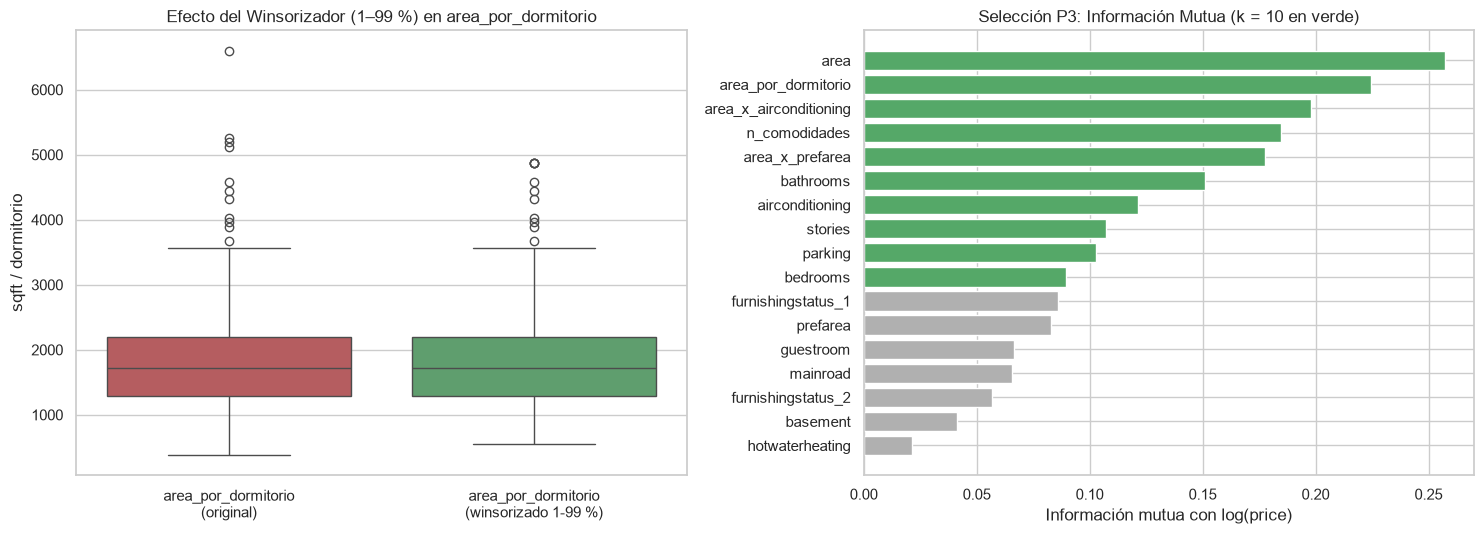

Figura guardada en: C:\Users\Windows 11\Desktop\ml-precio-vivienda\reports\figures\fig_prepro_p3_winsor_y_seleccion.png


In [10]:
# --- Figura 2: Efecto de la winsorización (P3) y ranking de Información Mutua ---
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Panel A: Boxplot comparativo de area_por_dormitorio antes vs después de winsorización (normalizado por mediana para visualizar)
df_w_plot = pd.DataFrame({
    "area_por_dormitorio\n(original)": X_deriv_raw["area_por_dormitorio"],
    "area_por_dormitorio\n(winsorizado 1-99 %)": X_deriv_win["area_por_dormitorio"],
})
sns.boxplot(data=df_w_plot, ax=axes[0], palette=["#C44E52", "#55A868"])
axes[0].set_title("Efecto del Winsorizador (1–99 %) en area_por_dormitorio")
axes[0].set_ylabel("sqft / dormitorio")

# Panel B: Puntajes de Información Mutua de todas las variables candidatas en P3
nombres_previos = list(Pipeline(pre_p3.steps[:-1]).get_feature_names_out())
scores_mi = pre_p3.named_steps["sel"].scores_
soporte = pre_p3.named_steps["sel"].get_support()

df_mi = pd.DataFrame({
    "variable": nombres_previos,
    "mi_score": scores_mi,
    "seleccionada": soporte,
}).sort_values("mi_score", ascending=True)

colores_mi = ["#55A868" if s else "#B0B0B0" for s in df_mi["seleccionada"]]
axes[1].barh(df_mi["variable"], df_mi["mi_score"], color=colores_mi)
axes[1].set_title("Selección P3: Información Mutua (k = 10 en verde)")
axes[1].set_xlabel("Información mutua con log(price)")

plt.tight_layout()
ruta_fig2 = DIR_FIGURAS / "fig_prepro_p3_winsor_y_seleccion.png"
fig.savefig(ruta_fig2, dpi=150, bbox_inches="tight")
plt.show()
print("Figura guardada en:", ruta_fig2)

**Comentario sobre P3:**  
1. El `Winsorizador(1, 99)` recorta únicamente los extremos superiores e inferiores aprendidos en `train_fold` (por ejemplo, valores extremos de `area` y `area_por_dormitorio`), reduciendo su asimetría sin eliminar observaciones válidas del mercado.
2. Las variables derivadas `area_por_dormitorio`, `n_comodidades`, `area_x_prefarea` y `area_x_airconditioning` aparecen con alta relevancia en el ranking de información mutua junto con `area` y `bathrooms`, mientras que las variables con menor señal quedan filtradas por `SelectKBest(k=10)`.

## 7. Comparación global, verificación de contratos y ausencia de fuga

Se verifica de manera sistemática para las tres estrategias (`P1`, `P2`, `P3`):
- Dimensiones consistentes entre entrenamiento (`train_fold`) y validación (`val_fold`).
- Cero valores `NaN` o infinitos en ambas particiones.
- Exacta correspondencia de columnas.
- Ausencia de fuga de información: si alteramos drásticamente `X_val` (`area * 100`), los parámetros aprendidos en `fit(X_train, y_train)` y las columnas seleccionadas en `P3` permanecen idénticos.

In [11]:
filas_contrato = []
X_val_extremo = X_val.copy()
X_val_extremo["area"] = X_val_extremo["area"] * 100

for p in ("P1", "P2", "P3"):
    pre_a = construir_preprocesamiento(p, escalar=True)
    Xt_tr = pre_a.fit_transform(X_train, y_train)
    Xt_va = pre_a.transform(X_val)

    arr_tr = np.asarray(Xt_tr, dtype=float)
    arr_va = np.asarray(Xt_va, dtype=float)
    mismas_cols = (
        list(Xt_tr.columns) == list(Xt_va.columns)
        if isinstance(Xt_tr, pd.DataFrame) and isinstance(Xt_va, pd.DataFrame)
        else Xt_tr.shape[1] == Xt_va.shape[1]
    )

    # Verificar que transformar datos extremos no produce NaN y que las columnas seleccionadas no cambian
    Xt_ext = np.asarray(pre_a.transform(X_val_extremo), dtype=float)
    assert not np.isnan(Xt_ext).any()

    filas_contrato.append({
        "estrategia": p,
        "shape_train": str(Xt_tr.shape),
        "shape_val": str(Xt_va.shape),
        "nans_train": int(np.isnan(arr_tr).sum()),
        "nans_val": int(np.isnan(arr_va).sum()),
        "mismas_columnas": bool(mismas_cols),
        "transformacion_objetivo": "Escala original" if p == "P1" else "log(price) [TransformedTargetRegressor]",
    })

df_contratos = pd.DataFrame(filas_contrato)
display(df_contratos)

,estrategia,shape_train,shape_val,nans_train,nans_val,mismas_columnas,transformacion_objetivo
0,P1,"(348, 13)","(88, 13)",0,0,True,Escala original
1,P2,"(348, 13)","(88, 13)",0,0,True,log(price) [TransformedTargetRegressor]
2,P3,"(348, 10)","(88, 10)",0,0,True,log(price) [TransformedTargetRegressor]


## 8. T18 · Variables derivadas justificadas

Con base en la teoría de precios hedónicos y los hallazgos del EDA (T07), se construyen cuatro variables derivadas mediante fórmulas deterministas por fila (`DerivadorVariablesT18` en `src/ingenieria.py`), sin utilizar estadísticos muestrales:

1. **`habitaciones_totales` (`bedrooms + bathrooms`):** resume la capacidad funcional total de la vivienda.
2. **`banos_por_habitacion` (`bathrooms / bedrooms`):** mide la densidad sanitaria o nivel de confort por dormitorio (división segura porque `bedrooms >= 1` fue verificado en T06).
3. **`n_comodidades` (`guestroom + basement + hotwaterheating + airconditioning`):** conteo agregado de equipamiento (0–4), que reduce la varianza de indicadores binarios poco frecuentes como `hotwaterheating` (5,05 % en entrenamiento).
4. **`log_area` (`np.log(area)`):** corrige la fuerte asimetría derecha del tamaño del lote y captura rendimientos marginales decrecientes.

In [12]:
from src.ingenieria import (
    COLUMNAS_DERIVADAS_T18,
    ablar_furnishingstatus,
    comparar_seleccion_cv,
    justificar_variables_derivadas,
)

df_derivadas = justificar_variables_derivadas(X, y)
df_derivadas.to_csv(DIR_TABLAS / "t18_variables_derivadas.csv", index=False)
display(df_derivadas)

,variable,min,media,mediana,max,asimetria,pearson_price,pearson_log_price,spearman_price,p_valor_log
0,habitaciones_totales,2.0000,4.2248,4.0000,8.0000,0.7158,0.5313,0.5164,0.5191,0.0000
1,banos_por_habitacion,0.2000,0.4472,0.4000,1.0000,1.1930,0.2329,0.1969,0.1727,0.0000
2,n_comodidades,0.0000,0.8807,1.0000,3.0000,0.7244,0.4648,0.4939,0.5291,0.0000
3,log_area,7.4085,8.4645,8.4152,9.6928,0.0848,0.5463,0.5677,0.5954,0.0000


## 9. T18 · Comparación de selección de variables dentro de la CV

Se comparan tres métodos de selección ejecutados **estrictamente dentro de cada uno de los 15 pliegues** (CV estratificada repetida 5×3 sobre `log(price)`):
- **Información Mutua (`MI`):** `SelectKBest(mutual_info_regression, k=10)`.
- **Lasso (`LASSO`):** `LassoCV(cv=5)` con umbral `|coef| > 1e-6`.
- **Eliminación Recursiva (`RFE`):** `RFE(Ridge(alpha=1.0), n_features_to_select=10)`.

Además, se evalúa el desempeño fuera de muestra (RMSE en la escala original de `price`) de cinco modelos representativos (`M1`, `M2`, `M4`, `M5`, `M6`) con cada selector y sin selección.

--- Estabilidad y consenso por variable (15 pliegues) ---


,variable,freq_mi_pct,mi_score_media,freq_lasso_pct,lasso_abs_coef_media,freq_rfe_pct,rfe_rank_media,freq_promedio_pct,consenso_3_metodos
0,log_area,100.0000,0.2959,100.0000,0.1697,100.0000,1.0000,100.0000,3
1,stories,100.0000,0.1405,100.0000,0.0730,93.3333,1.0667,97.7778,3
2,bathrooms,100.0000,0.1361,100.0000,0.1210,93.3333,1.2000,97.7778,3
3,n_comodidades,100.0000,0.1882,100.0000,0.0818,86.6667,1.2000,95.5556,3
4,airconditioning,93.3333,0.1170,100.0000,0.0702,73.3333,1.6667,88.8889,3
5,area,100.0000,0.2862,100.0000,0.0567,20.0000,2.7333,73.3333,2
6,furnishingstatus_1,20.0000,0.0674,100.0000,0.1301,100.0000,1.0000,73.3333,2
7,mainroad,6.6667,0.0655,100.0000,0.0846,100.0000,1.0000,68.8889,2
8,parking,100.0000,0.1205,100.0000,0.0386,6.6667,3.6000,68.8889,2
9,prefarea,0.0000,0.0547,100.0000,0.1185,100.0000,1.0000,66.6667,2



--- RMSE medio fuera de muestra por selector y modelo ---


selector,LASSO,MI,RFE,Sin selección (todas)
modelo_nombre,,,,
OLS (hedónico),"1,083,659.7284","1,134,880.7327","1,132,030.8189","1,083,639.8415"
Random Forest,"1,139,709.4240","1,179,963.5548","1,176,060.1907","1,137,678.0415"
Ridge,"1,081,212.6763","1,134,317.5328","1,129,745.6090","1,081,542.7812"
SVR (RBF),"1,227,573.0443","1,308,236.7290","1,272,217.4494","1,220,999.1650"
XGBoost,"1,110,611.9499","1,164,354.3827","1,144,132.0147","1,102,961.5607"


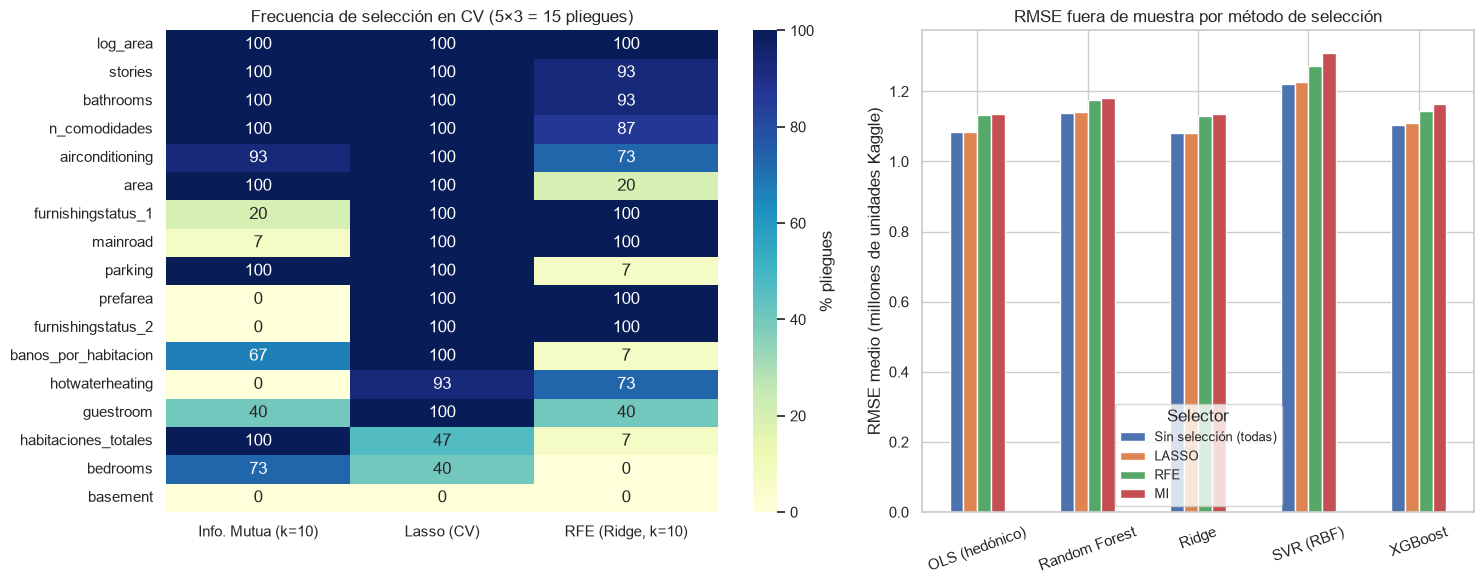

In [13]:
resumen_vars, por_pliegue_sel, resumen_sel = comparar_seleccion_cv(X, y, pliegues)
resumen_vars.to_csv(DIR_TABLAS / "t18_seleccion_variables_frecuencia.csv", index=False)
resumen_sel.to_csv(DIR_TABLAS / "t18_seleccion_modelos_rmse.csv", index=False)

print("--- Estabilidad y consenso por variable (15 pliegues) ---")
display(resumen_vars)
print("\n--- RMSE medio fuera de muestra por selector y modelo ---")
display(resumen_sel.pivot(index="modelo_nombre", columns="selector", values="rmse_media"))

# Figura T18-1: Frecuencia de selección por método y RMSE por selector
fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1.25, 1]})

df_heat = resumen_vars.set_index("variable")[["freq_mi_pct", "freq_lasso_pct", "freq_rfe_pct"]]
df_heat.columns = ["Info. Mutua (k=10)", "Lasso (CV)", "RFE (Ridge, k=10)"]
sns.heatmap(df_heat, annot=True, fmt=".0f", cmap="YlGnBu", vmin=0, vmax=100, ax=axes[0], cbar_kws={"label": "% pliegues"})
axes[0].set_title("Frecuencia de selección en CV (5×3 = 15 pliegues)")
axes[0].set_ylabel("")

piv = resumen_sel.pivot(index="modelo_nombre", columns="selector", values="rmse_media")
orden_cols = [c for c in ["Sin selección (todas)", "LASSO", "RFE", "MI"] if c in piv.columns]
(piv[orden_cols] / 1e6).plot(kind="bar", ax=axes[1], rot=20)
axes[1].set_title("RMSE fuera de muestra por método de selección")
axes[1].set_ylabel("RMSE medio (millones de unidades Kaggle)")
axes[1].set_xlabel("")
axes[1].legend(title="Selector", fontsize=9)

plt.tight_layout()
plt.savefig(DIR_FIGURAS / "fig_t18_seleccion_comparacion.png", dpi=150, bbox_inches="tight")
plt.show()

**Análisis de qué variables se conservan y por qué:**

1. **Consenso unánime (3/3 métodos en >= 73 % de los pliegues):** `log_area` (100 % en los tres), `stories` (97,8 %), `bathrooms` (97,8 %), `n_comodidades` (95,6 %) y `airconditioning` (88,9 %). Dos de las cuatro variables derivadas (`log_area` y `n_comodidades`) se consolidan en el núcleo más estable.
2. **Por qué Lasso supera a MI y RFE:** Lasso obtiene el menor RMSE entre los selectores en todos los modelos (y en Ridge mejora ligeramente frente a usar las 17 variables: 1.081.213 vs 1.081.543), porque elimina consistentemente `basement` (0 % en los tres métodos, ya absorbida por `n_comodidades`) y reduce la colinealidad de `bedrooms` / `habitaciones_totales` sin imponer un recorte rígido `k=10`. En contraste, `MI` univariada penaliza variables binarias de alto valor hedónico como `prefarea` (0 %), `mainroad` (6,7 %) y `furnishingstatus_2` (0 %), elevando el RMSE entre +4,7 % y +5,0 %.
3. **Variables conservadas:** se recomienda conservar la selección adaptativa de **Lasso** (o el conjunto completo excluyendo `basement`, cuya información queda representada por `n_comodidades`).

## 10. T18 · Ablación de `furnishingstatus` (Hipótesis H3)

`furnishingstatus` fue añadida en la versión de Kaggle sin documentación de origen ni criterio de codificación. Para contrastar **H3**, se entrena y evalúa cada uno de los seis modelos (`M1`–`M6`) **con y sin `furnishingstatus`** sobre los mismos 15 pliegues, reportando `delta_rmse = RMSE_sin - RMSE_con`, su desviación estándar entre pliegues y la prueba *t* corregida de Nadeau & Bengio (2003) para validación cruzada repetida.

,modelo,modelo_nombre,rmse_con_media,rmse_sin_media,delta_rmse_media,delta_rmse_desv,delta_rmse_pct,ic95_inf,ic95_sup,t_stat,p_valor,significativo_005
0,M1,OLS (hedónico),"1,083,639.8415","1,090,575.8563","6,936.0148","35,541.3567",0.6360,"-35,960.2308","49,832.2604",0.3468,0.7339,False
1,M2,Ridge,"1,081,542.7812","1,089,324.9146","7,782.1334","34,390.8099",0.7144,"-33,725.4725","49,289.7393",0.4021,0.6937,False
2,M3,KNN,"1,195,199.8486","1,209,490.4850","14,290.6365","18,367.5521",1.1815,"-7,877.8765","36,459.1494",1.3826,0.1884,False
3,M4,SVR (RBF),"1,220,999.1650","1,218,071.9464","-2,927.2185","41,283.0989",-0.2403,"-52,753.3960","46,898.9590",-0.1260,0.9015,False
4,M5,Random Forest,"1,137,678.0415","1,156,269.8681","18,591.8265","21,227.5893",1.6079,"-7,028.5765","44,212.2296",1.5564,0.1419,False
5,M6,XGBoost,"1,102,961.5607","1,120,971.5448","18,009.9841","32,223.3369",1.6066,"-20,881.6143","56,901.5825",0.9932,0.3375,False


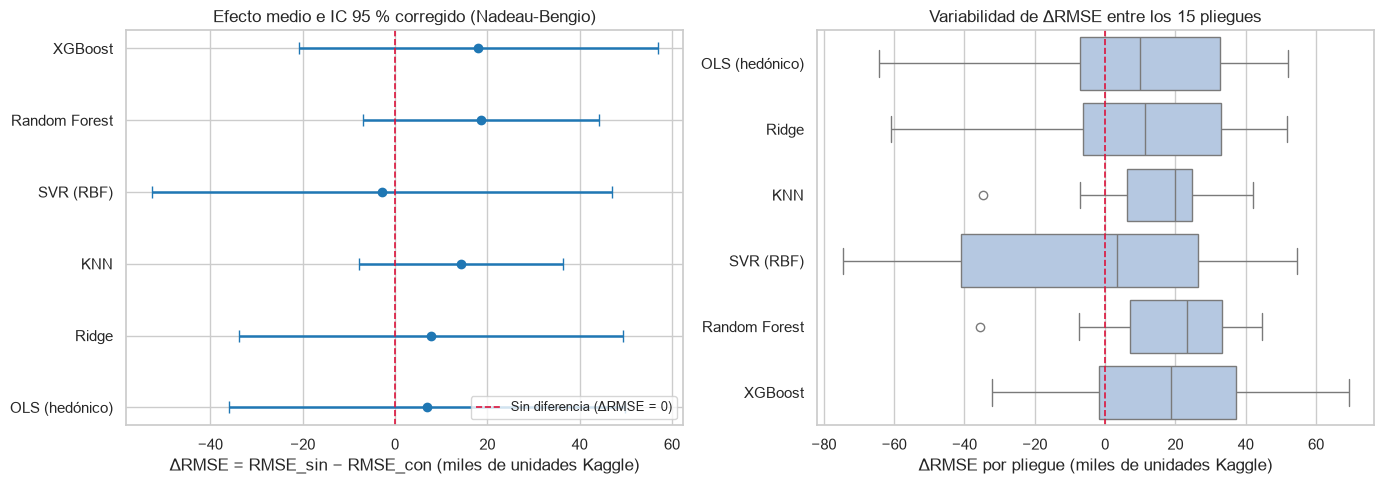

In [14]:
ablacion_pliegues, ablacion_resumen = ablar_furnishingstatus(X, y, pliegues)
ablacion_resumen.to_csv(DIR_TABLAS / "t18_ablacion_furnishingstatus.csv", index=False)
display(ablacion_resumen[[
    "modelo", "modelo_nombre", "rmse_con_media", "rmse_sin_media",
    "delta_rmse_media", "delta_rmse_desv", "delta_rmse_pct",
    "ic95_inf", "ic95_sup", "t_stat", "p_valor", "significativo_005"
]])

# Figura T18-2: Diferencia de RMSE (sin - con) con IC 95% corregido y variabilidad por pliegue
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

y_pos = np.arange(len(ablacion_resumen))
err_inf = (ablacion_resumen["delta_rmse_media"] - ablacion_resumen["ic95_inf"]) / 1e3
err_sup = (ablacion_resumen["ic95_sup"] - ablacion_resumen["delta_rmse_media"]) / 1e3
axes[0].errorbar(
    ablacion_resumen["delta_rmse_media"] / 1e3, y_pos,
    xerr=[err_inf, err_sup], fmt="o", color="#1f77b4", capsize=4, lw=1.8
)
axes[0].axvline(0, color="crimson", linestyle="--", lw=1.2, label="Sin diferencia (ΔRMSE = 0)")
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(ablacion_resumen["modelo_nombre"])
axes[0].set_xlabel("ΔRMSE = RMSE_sin − RMSE_con (miles de unidades Kaggle)")
axes[0].set_title("Efecto medio e IC 95 % corregido (Nadeau-Bengio)")
axes[0].legend(loc="lower right", fontsize=9)

sns.boxplot(
    data=ablacion_pliegues.assign(delta_miles=ablacion_pliegues["delta_rmse"] / 1e3),
    x="delta_miles", y="modelo_nombre", ax=axes[1], color="#aec7e8"
)
axes[1].axvline(0, color="crimson", linestyle="--", lw=1.2)
axes[1].set_xlabel("ΔRMSE por pliegue (miles de unidades Kaggle)")
axes[1].set_ylabel("")
axes[1].set_title("Variabilidad de ΔRMSE entre los 15 pliegues")

plt.tight_layout()
plt.savefig(DIR_FIGURAS / "fig_t18_ablacion_furnishingstatus.png", dpi=150, bbox_inches="tight")
plt.show()

## 11. Conclusiones integradas (T17 · T18) y texto para el paper

1. **Estrategias P1–P3 (T17):** `P1` estandariza escalas conservando asimetrías; `P2` corrige las colas derechas de `area` y `price` (`Yeo-Johnson` + `log(price)`); `P3` añade winsorización y selección dentro del fold sin fuga de información.
2. **Variables derivadas (T18):** `log_area` (`r = 0,568` con `log(price)`, asimetría `0,085`) y `n_comodidades` (`r = 0,494`) son las derivadas más informativas y alcanzan consenso en los tres métodos de selección.
3. **Selección de variables en CV (T18):** **Lasso** ofrece el mejor balance entre parsimonia y RMSE fuera de muestra en todas las familias de modelos, descartando `basement` el 100 % de las veces. El recorte fijo `k=10` de MI penaliza variables binarias clave (`prefarea`, `mainroad`) y degrada el RMSE.
4. **Ablación de `furnishingstatus` — Conclusión para el paper (consistente con H3):**
   - *Español:* En las seis familias de modelos evaluadas mediante validación cruzada estratificada repetida 5×3, la exclusión de `furnishingstatus` produce diferencias medias de RMSE entre `-42` (`-0,24 %` en SVR) y `+266` (`+1,61 %` en Random Forest) CAD de 1987 (equivalente a `-2.927` y `+18.592` unidades Kaggle ÷ 70), con alta variabilidad entre pliegues (`DE = 262` a `590` CAD de 1987) y sin significancia estadística bajo la prueba *t* corregida de Nadeau-Bengio (todos los `p >= 0,142`; todos los IC 95 % incluyen el cero). Resultado consistente con **H3**: `furnishingstatus` puede omitirse sin pérdida significativa de capacidad predictiva.
   - *English (IEEE paper draft):* *Across all six model families evaluated under 5×3 repeated stratified cross-validation, ablating the undocumented Kaggle-added `furnishingstatus` feature yields small mean RMSE differences ranging from −42 (−0.24%, SVR) to +266 (+1.61%, Random Forest) 1987 CAD, accompanied by substantial fold-to-fold variability (SD 262–590 1987 CAD). Under the Nadeau–Bengio corrected resampled t-test, none of the differences is statistically significant (all p ≥ 0.142; all 95% CIs span zero). These results are consistent with H3 and justify omitting `furnishingstatus` without degrading predictive accuracy.*